# Data Preparation

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 28.04.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
import os
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import pyensembl
import scanpy as sc
import squidpy as sq

import nichejepa

INFO:datasets:PyTorch version 2.1.2 available.
INFO:datasets:Polars version 0.20.22 available.
INFO:datasets:JAX version 0.4.26 available.


### 1.2 Run Notebook Setup

In [2]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

Run ```pyensembl install --release 111 --species homo_sapiens```.

In [3]:
ensembl = pyensembl.EnsemblRelease(111)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"

# Create required directories
os.makedirs(st_data_bronze_folder_path, exist_ok=True)
os.makedirs(st_data_silver_folder_path, exist_ok=True)
os.makedirs(st_data_gold_folder_path, exist_ok=True)

## 2. Manuscript Data

### 2.1 Nanostring CosMx Human Brain

- Data Access: https://nanostring.com/products/cosmx-spatial-molecular-imager/ffpe-dataset/human-frontal-cortex-ffpe-dataset/

In [5]:
# Read data
df = pd.read_csv(f"{st_data_bronze_folder_path}/S3_exprMat_file.csv.gz")
df_metadata = pd.read_csv(f"{st_data_bronze_folder_path}/S3_metadata_file.csv.gz")

#### 2.1.1 Preprocess Data

In [6]:
## Create adata object
# Only keep genes
genes = [col for col in df.columns if
         ("FalseCode" not in col) &
         ("NegPrb" not in col) &
         ("Custom" not in col) &
         ("cell" not in col) &
         ("fov" not in col)]
df_counts = df[genes]

genes = [gene.split("/")[0] for gene in df_counts.columns]

# Rename some genes with names from Ensembl database
for old_gene_name, new_gene_name in zip(["BAGE", "LILRA3", "COX1", "COX2", "CT45A", "HLA-DRB", "LOC728392", "METTL7A", "SLC9A3R1", "TTC30A"],
                                        ["BAGE2", "ENSG00000275841", "MT-CO1", "MT-CO2", "CT45A1", "HLA-DRB1", "ENSG00000286190", "TMT1A", "NHERF1", "IFT70A"]):
    idx = genes.index(old_gene_name)
    genes[idx] = new_gene_name
    
df_counts.columns = genes

var_metadata = pd.DataFrame(index=df_counts.columns)
obs_metadata = pd.DataFrame(index=df_counts.index, data={"fov": df["fov"].values,
                                                         "cell_id": df["cell_ID"].values,
                                                         "cell": df["cell"].values})

adata = ad.AnnData(X=df_counts.values, obs=obs_metadata, var=var_metadata)

adata.obs["niche_type"] = df_metadata["spatialClusteringAssignments"].values
adata.obs["cell_type"] = df_metadata["RefinedClusts_Final"].values

# Convert pixel value to micron
adata.obsm["spatial"] = np.array(
    df_metadata[["CenterX_global_px", "CenterY_global_px"]] * 0.12)

# Get ensembl ids
genes = adata.var.index.tolist()
ensembl_ids = []
for gene in genes:
    try:
        ensembl_ids.append(ensembl.gene_ids_of_gene_name(gene)[0])
    except ValueError as e:
        ensembl_ids.append(gene)
        print(f"Gene {gene} not found in Ensembl release.")
adata.var["ensembl_id"] = ensembl_ids

# Compute spatial neighborhood based on Visium spot diameter of 55 microns
spatial_key = "spatial"

sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key=spatial_key,
                        radius=55)

# Compute counts per neighborhood (sum pooling)
adata.layers["counts_neighborhood"] = np.array(
    (adata.obsp["spatial_connectivities"].T @ adata.X))
    # / adata.obsp["spatial_connectivities"].sum(0).T)

adata.layers["counts"] = adata.X

adata.write(f"{st_data_silver_folder_path}/nanostring_cosmx_human_brain.h5ad")

Gene ENSG00000275841 not found in Ensembl release.
Gene ENSG00000286190 not found in Ensembl release.
Gene MHC I not found in Ensembl release.


... storing 'niche_type' as categorical
... storing 'cell_type' as categorical


#### 2.1.2 Visualize Data

In [7]:
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/nanostring_cosmx_human_brain.h5ad")

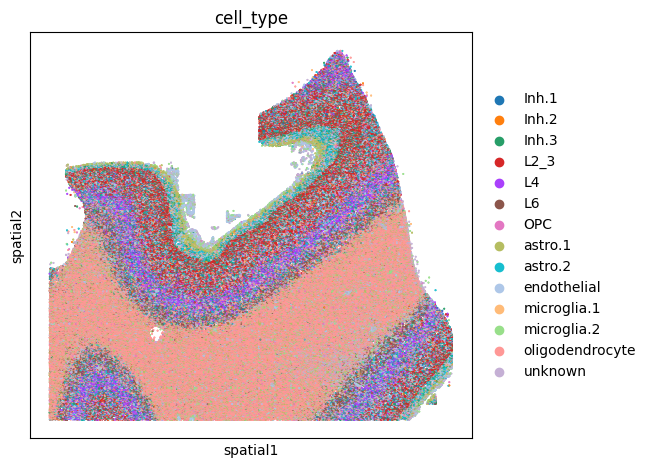

In [8]:
# Visualize cell types in tissue
sq.pl.spatial_scatter(adata, color="cell_type", shape=None) 

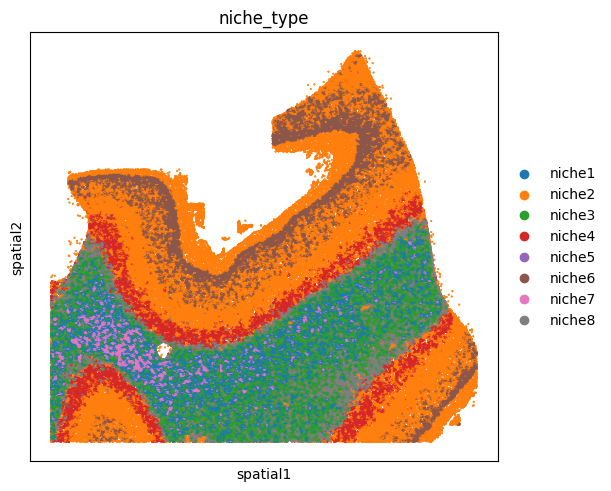

In [9]:
# Visualize niche types in tissue
sq.pl.spatial_scatter(adata, color="niche_type", shape=None) 

In [10]:
# Compute UMAP based on counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

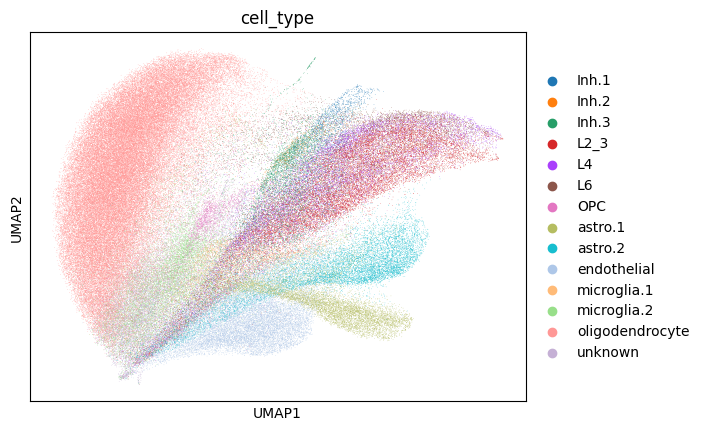

In [11]:
# Visualize cell types in count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

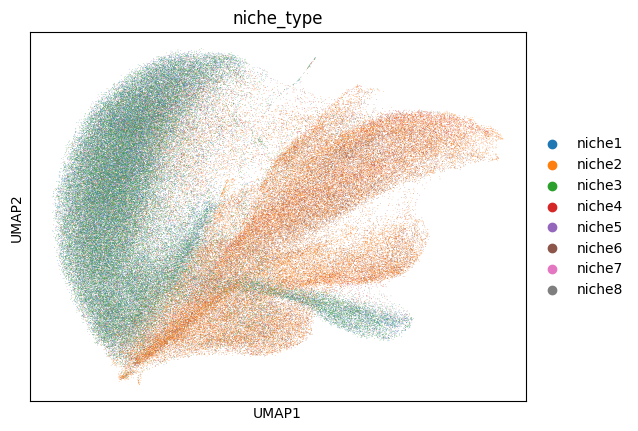

In [12]:
# Visualize niche types in count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [14]:
# Compute UMAP based on neighborhood counts
sc.pp.pca(adata, layer="counts_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

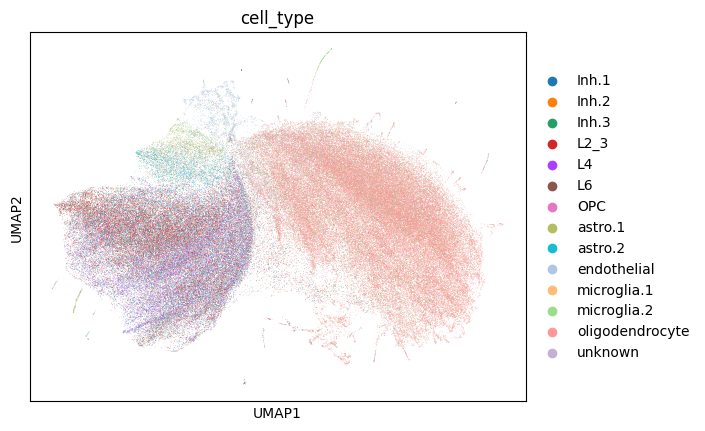

In [15]:
# Visualize cell types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

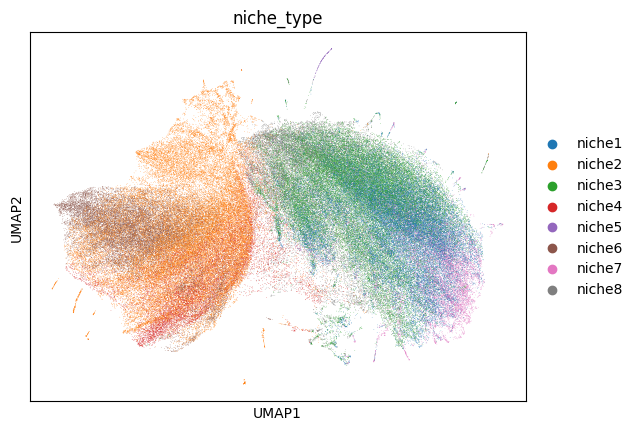

In [16]:
# Visualize niche types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])